In [1]:
# ============================================================
# 128版 VoxelMorph + 非ダウンサンプリングSWT（LL / HH分岐）用
# 人工DVFの教師あり事前学習 + 逆写像整合性制約
#
# 前提:
# - 同じ環境で読み込まれる voxelmorph.networks.VxmDense1 が、
#   入力画像に対して「非ダウンサンプリングSWT → LL/HH分岐」を
#   内部で実装していること。
# - このセルの generator は生CTを渡すだけで、ここでは
#   ウェーブレット変換を行わない。
# ============================================================

import os
os.environ["VXM_BACKEND"] = "pytorch"

import numpy as np
import torch
import torch.nn.functional as F
import torch.optim as optim
import scipy.ndimage
import matplotlib.pyplot as plt

from scipy.ndimage import gaussian_filter
from tqdm.notebook import tqdm
from IPython.display import clear_output

import voxelmorph as vxm



backend:pytorch
Pytorch


In [14]:
# ============================================================
# 1. 設定
# ============================================================

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

data_path = "CT_Train_NoBed.npz"
data_key = "Train"

batch_size = 2
epochs = 40000
learning_rate = 1e-4

# 損失の重み
image_weight = 100.0
flow_weight = 0.1
inverse_weight = 0.2

# 人工DVFの設定
initial_shift_range = 1
shift_increment_interval = 1000
coarse_flow_shape = (8, 16, 16)
gaussian_sigma = 2.0

# チェックポイント保存間隔
save_interval = 1000

print(f"device: {device}")



device: cuda:0


In [4]:
from pathlib import Path

print("現在の作業フォルダ:", Path.cwd())

data_path = Path(r"D:\Saito\Data\TrainData_NoBed.npz")
data_key = "Train"

if not data_path.is_file():
    raise FileNotFoundError(f"見つかりません: {data_path}")

raw_train = np.load(data_path)[data_key]

現在の作業フォルダ: d:\Saito


In [5]:
# ============================================================
# 2. CTデータ読み込み・128版へ縮小
#    入力想定: (D, H, W, N)
#    出力形状: (N, 64, 128, 128)
# ============================================================

raw_train = np.load(data_path)[data_key]

# (D, H, W, N) -> (N, D, H, W)
x_train = np.transpose(raw_train, (3, 0, 1, 2)).astype(np.float32)

# 例: (N, 128, 256, 256) -> (N, 64, 128, 128)
x_train = scipy.ndimage.zoom(
    x_train,
    zoom=(1.0, 0.5, 0.5, 0.5),
    order=3,
).astype(np.float32)

print(f"x_train shape: {x_train.shape}")

if x_train.ndim != 4:
    raise ValueError(
        f"x_train は (N, D, H, W) である必要があります。現在: {x_train.shape}"
    )

_, D, H, W = x_train.shape

if (D, H, W) != (64, 128, 128):
    raise ValueError(
        "VxmDense1の入力サイズとデータサイズが一致していません。"
        f"期待: (64, 128, 128), 実際: {(D, H, W)}"
    )



x_train shape: (400, 64, 128, 128)


In [6]:

# ============================================================
# 3. 生CT画像を返すジェネレーター
#    SWT・LL/HH分岐は VxmDense1 内部で実行する
# ============================================================

def image_generator(x_data, batch_size):
    """
    返す画像は生CT。
    形状: (B, 1, D, H, W)
    """
    n_samples = x_data.shape[0]

    while True:
        indices = np.random.randint(0, n_samples, size=batch_size)

        # (B, D, H, W) -> (B, 1, D, H, W)
        moving_images = torch.from_numpy(
            x_data[indices]
        ).unsqueeze(1).float()

        yield moving_images


train_generator = image_generator(x_train, batch_size=batch_size)



In [7]:
# ============================================================
# 4. 非ダウンサンプリングSWT LL/HH分岐を内部に持つモデル
# ============================================================

nb_features = [
    [32, 64, 64, 64, 64],
    [64, 64, 64, 64, 64, 32, 16, 16],
]

# int_steps=0:
# 返されるVecと、SpatialTransformerで使うDVFを同じ規約・単位にする
model3D = vxm.networks.VxmDense1(
    (D, H, W),
    nb_features,
    int_steps=0,
).to(device)

optimizer = optim.Adam(model3D.parameters(), lr=learning_rate)
mse_loss = vxm.losses.MSE().loss

# 画像とDVFをVoxelMorphの規約でワープする
transformer = vxm.layers.SpatialTransformer((D, H, W)).to(device)

print(model3D.__class__.__name__)



5
6
7
6
7
6
7
6
7
6
7
64
128
8
9
64
10
8
9
64
10
8
9
64
10
8
9
64
10
8
9
64
10
11
11
11
[32, 64, 64]
VxmDense1


c:\Users\user\anaconda3\envs\nn\lib\site-packages\torch\functional.py:507: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at C:\cb\pytorch_1000000000000\work\aten\src\ATen\native\TensorShape.cpp:3550.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


In [8]:
# ============================================================
# 5. DVF補助関数
# ============================================================

def make_smooth_random_flow(
    batch_size,
    full_shape,
    shift_range,
    device,
    coarse_shape=(8, 16, 16),
    sigma=2.0,
):
    """
    滑らかな人工DVFを作成する。

    戻り値:
        flow: (B, 3, D, H, W)
        各成分はボクセル単位。
    """
    coarse_flow = (
        torch.rand(
            (batch_size, 3, *coarse_shape),
            device=device,
            dtype=torch.float32,
        ) * 2.0 - 1.0
    ) * shift_range

    # 人工教師DVFであり、勾配は不要
    coarse_flow_np = coarse_flow.detach().cpu().numpy()

    smooth_flow_np = gaussian_filter(
        coarse_flow_np,
        sigma=(0, 0, sigma, sigma, sigma),
    )

    smooth_flow = torch.from_numpy(
        smooth_flow_np
    ).to(device=device, dtype=torch.float32)

    # 粗いDVFを画像サイズまで補間
    flow = F.interpolate(
        smooth_flow,
        size=full_shape,
        mode="trilinear",
        align_corners=True,
    )

    return flow


def compose_flows(flow_ab, flow_ba, transformer):
    """
    VoxelMorphの座標規約でDVFを合成する。

    u_ba(x) + u_ab(x + u_ba(x))

    flow_ab:
        moving -> synthetic fixed のDVF
    flow_ba:
        synthetic fixed -> moving のDVF

    戻り値がゼロなら、両者は逆写像の関係にある。
    """
    flow_ab_at_ba = transformer(flow_ab, flow_ba)
    return flow_ba + flow_ab_at_ba


@torch.no_grad()
def invert_flow(flow_ab, transformer, n_iter=20):
    """
    forward DVF u_ab の逆DVF u_ba を固定点反復で近似する。

    u_ba(x) = -u_ab(x + u_ba(x))
    """
    flow_ba = torch.zeros_like(flow_ab)

    for _ in range(n_iter):
        flow_ba = -transformer(flow_ab, flow_ba)

    return flow_ba


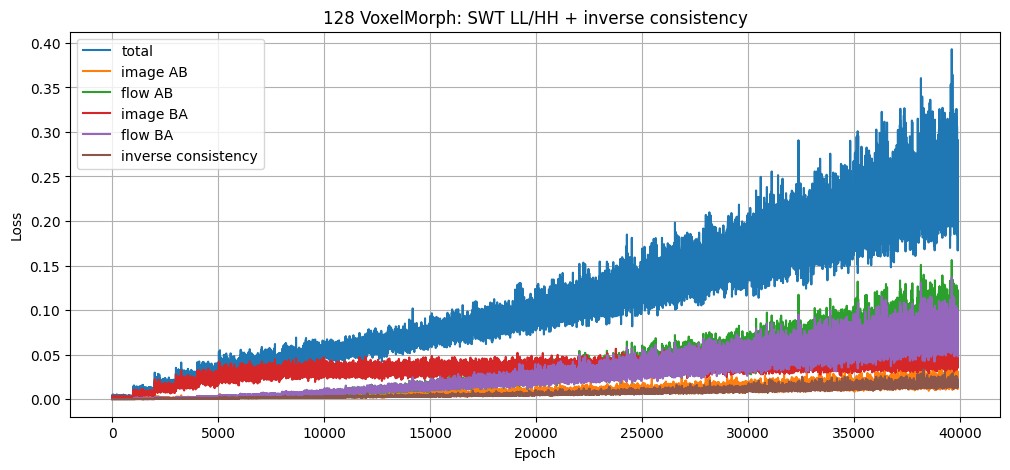

Epoch 39901/40000 | total=0.287659 | image_ab=0.030340 | flow_ab=0.096175 | image_ba=0.050222 | flow_ba=0.090004 | inverse=0.020918 | shift=±40
total=0.287659, flow_ab=0.096175, flow_ba=0.090004, inverse=0.020918, inverse_ratio=7.3%
torch.Size([2, 3, 64, 128, 128])
torch.Size([2, 1, 64, 128, 128])
torch.Size([2, 3, 64, 128, 128])
torch.Size([2, 1, 64, 128, 128])
torch.Size([2, 3, 64, 128, 128])
torch.Size([2, 1, 64, 128, 128])
torch.Size([2, 3, 64, 128, 128])
torch.Size([2, 1, 64, 128, 128])
torch.Size([2, 3, 64, 128, 128])
torch.Size([2, 1, 64, 128, 128])
torch.Size([2, 3, 64, 128, 128])
torch.Size([2, 1, 64, 128, 128])
torch.Size([2, 3, 64, 128, 128])
torch.Size([2, 1, 64, 128, 128])
torch.Size([2, 3, 64, 128, 128])
torch.Size([2, 1, 64, 128, 128])
torch.Size([2, 3, 64, 128, 128])
torch.Size([2, 1, 64, 128, 128])
torch.Size([2, 3, 64, 128, 128])
torch.Size([2, 1, 64, 128, 128])
torch.Size([2, 3, 64, 128, 128])
torch.Size([2, 1, 64, 128, 128])
torch.Size([2, 3, 64, 128, 128])
torch.Si

In [15]:

# ============================================================
# 6. 学習
# ============================================================

shift_range = initial_shift_range

losses = []
loss_images_ab = []
loss_vecs_ab = []
loss_images_ba = []
loss_vecs_ba = []
loss_invs = []

for epoch in tqdm(range(epochs)):

    # 徐々に大きい変形を学習させる
    if epoch > 0 and epoch % shift_increment_interval == 0:
        shift_range += 1
        print(f"Epoch {epoch}: shift range -> ±{shift_range} voxels")

    # --------------------------------------------------------
    # 生CTを取得
    # SWTはここでは行わず、モデル内部のLL/HH分岐へ渡す
    # --------------------------------------------------------
    moving_images = next(train_generator).to(device)
    current_batch_size = moving_images.shape[0]

    # --------------------------------------------------------
    # 人工的な順方向DVFと、synthetic fixedを作る
    # --------------------------------------------------------
    flow_ab_gt = make_smooth_random_flow(
        batch_size=current_batch_size,
        full_shape=(D, H, W),
        shift_range=shift_range,
        device=device,
        coarse_shape=coarse_flow_shape,
        sigma=gaussian_sigma,
    )

    # synthetic fixed = moving を flow_ab_gt で変形した画像
    with torch.no_grad():
        synthetic_fixed = transformer(moving_images, flow_ab_gt)

        # synthetic fixed -> moving の正しい逆方向教師DVF
        flow_ba_gt = invert_flow(
            flow_ab_gt,
            transformer,
            n_iter=20,
        )

    optimizer.zero_grad()

    # --------------------------------------------------------
    # 順方向: moving -> synthetic fixed
    # --------------------------------------------------------
    warped_ab, flow_ab_pred = model3D(
        moving_images,
        synthetic_fixed,
    )

    loss_image_ab = (
        mse_loss(synthetic_fixed, warped_ab) * image_weight
    )

    loss_vec_ab = (
        mse_loss(flow_ab_gt, flow_ab_pred) * flow_weight
    )

    # --------------------------------------------------------
    # 逆方向: synthetic fixed -> moving
    # --------------------------------------------------------
    warped_ba, flow_ba_pred = model3D(
        synthetic_fixed,
        moving_images,
    )

    loss_image_ba = (
        mse_loss(moving_images, warped_ba) * image_weight
    )

    # ここで必ず逆DVF flow_ba_gt を使う
    loss_vec_ba = (
        mse_loss(flow_ba_gt, flow_ba_pred) * flow_weight
    )

    # --------------------------------------------------------
    # 逆写像整合性
    # u_ba + u_ab(x + u_ba) ≈ 0
    # --------------------------------------------------------
    cycle_ba_ab = compose_flows(
        flow_ab_pred,
        flow_ba_pred,
        transformer,
    )

    # 反対の合成も評価して対称にする
    cycle_ab_ba = compose_flows(
        flow_ba_pred,
        flow_ab_pred,
        transformer,
    )

    loss_inv = (
        0.5 * (
            mse_loss(cycle_ba_ab, torch.zeros_like(cycle_ba_ab))
            + mse_loss(cycle_ab_ba, torch.zeros_like(cycle_ab_ba))
        )
        * inverse_weight
    )

    # --------------------------------------------------------
    # 総損失・更新
    # --------------------------------------------------------
    loss = (
        loss_image_ab
        + loss_vec_ab
        + loss_image_ba
        + loss_vec_ba
        + loss_inv
    )

    loss.backward()
    optimizer.step()

    # --------------------------------------------------------
    # 記録
    # --------------------------------------------------------
    losses.append(loss.item())
    loss_images_ab.append(loss_image_ab.item())
    loss_vecs_ab.append(loss_vec_ab.item())
    loss_images_ba.append(loss_image_ba.item())
    loss_vecs_ba.append(loss_vec_ba.item())
    loss_invs.append(loss_inv.item())

    # --------------------------------------------------------
    # 保存
    # --------------------------------------------------------
    if (epoch + 1) % save_interval == 0:
        checkpoint_path = (
            f"model_128_swt_inverse_epoch_{epoch + 1:05d}.pth"
        )

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": model3D.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "shift_range": shift_range,
                "loss": loss.item(),
            },
            checkpoint_path,
        )

    # --------------------------------------------------------
    # 表示
    # --------------------------------------------------------
    if epoch % 100 == 0:
        clear_output(wait=True)

        plt.figure(figsize=(12, 5))
        plt.plot(losses, label="total")
        plt.plot(loss_images_ab, label="image AB")
        plt.plot(loss_vecs_ab, label="flow AB")
        plt.plot(loss_images_ba, label="image BA")
        plt.plot(loss_vecs_ba, label="flow BA")
        plt.plot(loss_invs, label="inverse consistency")
        plt.xlabel("Epoch")
        plt.ylabel("Loss")
        plt.title("128 VoxelMorph: SWT LL/HH + inverse consistency")
        plt.grid(True)
        plt.legend()
        plt.show()

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"total={loss.item():.6f} | "
            f"image_ab={loss_image_ab.item():.6f} | "
            f"flow_ab={loss_vec_ab.item():.6f} | "
            f"image_ba={loss_image_ba.item():.6f} | "
            f"flow_ba={loss_vec_ba.item():.6f} | "
            f"inverse={loss_inv.item():.6f} | "
            f"shift=±{shift_range}"
        )
        
        inverse_ratio = loss_inv.item() / (loss.item() + 1e-8)

        print(
            f"total={loss.item():.6f}, "
            f"flow_ab={loss_vec_ab.item():.6f}, "
            f"flow_ba={loss_vec_ba.item():.6f}, "
            f"inverse={loss_inv.item():.6f}, "
            f"inverse_ratio={inverse_ratio:.1%}"
        )

In [11]:
# ============================================================
# 提案手法との整合性確認セル
# 1. 128×128×128版に揃うか
# 2. HU 0–1正規化済みか
# 3. VxmDense1がPRフィルタバンク LL/H 分岐か
# ============================================================

import os
from pathlib import Path
import inspect
import re
import numpy as np

# ------------------------------------------------------------
# 0. データファイル設定
# すでに data_path を定義済みなら、その値を使う。
# 未定義の場合は実際の場所に書き換える。
# ------------------------------------------------------------
if "data_path" not in globals():
    data_path = Path(r"C:\Users\user\Documents\CT_Train_NoBed.npz")
else:
    data_path = Path(data_path)

data_key = "Train"

if not data_path.is_file():
    raise FileNotFoundError(
        f"データが見つかりません:\n{data_path}\n\n"
        "data_path を CT_Train_NoBed.npz の実際のフルパスへ変更してください。"
    )

# ------------------------------------------------------------
# 1. NPZの内容と画像サイズ確認
# ------------------------------------------------------------
with np.load(data_path) as npz:
    print("=== NPZのキー ===")
    print(npz.files)

    if data_key not in npz.files:
        raise KeyError(
            f"キー '{data_key}' がありません。"
            f"利用可能なキー: {npz.files}"
        )

    raw_train = npz[data_key]

print("\n=== 読み込んだ配列 ===")
print(f"raw_train.shape : {raw_train.shape}")
print(f"raw_train.dtype : {raw_train.dtype}")

if raw_train.ndim != 4:
    raise ValueError(
        "4次元配列を想定しています。"
        f"現在の次元数: {raw_train.ndim}"
    )

# 先輩コードと同じ前提:
# raw_train = (D, H, W, N)
D_raw, H_raw, W_raw, N = raw_train.shape

print("\n=== 先輩コードの想定 ===")
print(f"入力形式         : (D, H, W, N)")
print(f"空間サイズ       : ({D_raw}, {H_raw}, {W_raw})")
print(f"症例数           : {N}")

# 全軸を1/2にする現在の前処理を想定
half_shape = (D_raw // 2, H_raw // 2, W_raw // 2)

print("\n=== 全軸を1/2にした場合 ===")
print(f"縮小後サイズ     : {half_shape}")

if half_shape == (128, 128, 128):
    print("✅ スライドの 128×128×128 と一致します。")
elif half_shape == (64, 128, 128):
    print("⚠️ 現在の全軸1/2縮小では 64×128×128 になります。")
    print("   スライドの 128×128×128 とは一致しません。")
    print("   例: 元画像が 128×256×256 の場合、Z軸を半分にしてはいけません。")
else:
    print("⚠️ スライドの 128×128×128 と一致しません。")
    print("   前処理の zoom 値と model の inshape を個別に調整してください。")

# ------------------------------------------------------------
# 2. 正規化の確認
#    全症例ではなく最大5症例を抽出して確認する
# ------------------------------------------------------------
sample_count = min(5, N)
sample_indices = np.linspace(0, N - 1, sample_count, dtype=int)

# raw_train は (D, H, W, N) を想定
sample = raw_train[..., sample_indices].astype(np.float32)

sample_min = float(np.nanmin(sample))
sample_max = float(np.nanmax(sample))
sample_mean = float(np.nanmean(sample))
sample_std = float(np.nanstd(sample))

print("\n=== 正規化確認（最大5症例のサンプル） ===")
print(f"sample indices    : {sample_indices.tolist()}")
print(f"min               : {sample_min:.6f}")
print(f"max               : {sample_max:.6f}")
print(f"mean              : {sample_mean:.6f}")
print(f"std               : {sample_std:.6f}")

if sample_min >= -1e-6 and sample_max <= 1.0 + 1e-6:
    print("✅ サンプル上は 0–1 の範囲です。")
    print("   スライドの『HUを0–1に正規化』と整合します。")
else:
    print("⚠️ サンプルは 0–1 の範囲ではありません。")
    print("   NPZ保存前に正規化されていない可能性があります。")
    print("   HU値そのものなら、学習前にwindowing・clip・0–1正規化が必要です。")

# ------------------------------------------------------------
# 3. VxmDense1内部のPRフィルタバンク確認
# ------------------------------------------------------------
print("\n=== VxmDense1の実装確認 ===")

try:
    import voxelmorph as vxm

    vxm_dense_source = inspect.getsource(vxm.networks.VxmDense1)

    # VxmDense1がどのU-Netクラスを使用しているか取得
    unet_match = re.search(
        r"self\.unet_model\s*=\s*([A-Za-z_][A-Za-z0-9_]*)\(",
        vxm_dense_source,
    )

    if unet_match is None:
        print("⚠️ VxmDense1から内部U-Netクラス名を自動取得できませんでした。")
        print("   networks.py の VxmDense1 を手動で確認してください。")
    else:
        unet_class_name = unet_match.group(1)
        print(f"VxmDense1が使う内部ネットワーク: {unet_class_name}")

        if not hasattr(vxm.networks, unet_class_name):
            print(f"⚠️ vxm.networks に {unet_class_name} が見つかりません。")
        else:
            unet_class = getattr(vxm.networks, unet_class_name)
            unet_source = inspect.getsource(unet_class)

            pr_markers = [
                "get_filter_kernel",
                "apply_3d_filter",
                "apply_3d_filterLL",
                "HLFH",
                "HHFH",
            ]

            swt_markers = [
                "pywt.swtn",
                "pywt.swt",
            ]

            detected_pr_markers = [
                marker for marker in pr_markers
                if marker in unet_source
            ]

            detected_swt_markers = [
                marker for marker in swt_markers
                if marker in unet_source
            ]

            print(f"PRフィルタバンク関連の検出: {detected_pr_markers}")
            print(f"SWT関連の検出            : {detected_swt_markers}")

            if (
                "get_filter_kernel" in unet_source
                and "apply_3d_filter" in unet_source
                and "apply_3d_filterLL" in unet_source
            ):
                print("✅ PRフィルタバンク型のLL/H分岐を検出しました。")
                print("   スライド8・9の構成と整合する候補です。")

            elif "pywt.swtn" in unet_source:
                print("⚠️ このVxmDense1はPRフィルタバンクではなくSWT実装です。")
                print("   スライド8・9のPRフィルタバンク構成とは別実装です。")

            else:
                print("⚠️ PRフィルタバンク型か自動判定できませんでした。")
                print("   networks.py内でLL/H成分の生成処理を確認してください。")

            # 画像解像度を保つ実装かの簡易確認
            if "source.cpu().numpy()" in unet_source:
                print("参考: 入力画像をNumPy化して周波数分解する実装です。")

except Exception as e:
    print(f"⚠️ VoxelMorph実装の確認中にエラー: {type(e).__name__}: {e}")

# ------------------------------------------------------------
# 最終判定用メモ
# ------------------------------------------------------------
print("\n=== 最終確認ポイント ===")
print("1. 画像サイズが (128, 128, 128) か")
print("2. 入力値が 0–1 の範囲か")
print("3. VxmDense1 が PRフィルタバンクのLL/H分岐を使っているか")

=== NPZのキー ===
['Train']

=== 読み込んだ配列 ===
raw_train.shape : (128, 256, 256, 400)
raw_train.dtype : float64

=== 先輩コードの想定 ===
入力形式         : (D, H, W, N)
空間サイズ       : (128, 256, 256)
症例数           : 400

=== 全軸を1/2にした場合 ===
縮小後サイズ     : (64, 128, 128)
⚠️ 現在の全軸1/2縮小では 64×128×128 になります。
   スライドの 128×128×128 とは一致しません。
   例: 元画像が 128×256×256 の場合、Z軸を半分にしてはいけません。

=== 正規化確認（最大5症例のサンプル） ===
sample indices    : [0, 99, 199, 299, 399]
min               : 0.000000
max               : 1.000000
mean              : 0.200521
std               : 0.264310
✅ サンプル上は 0–1 の範囲です。
   スライドの『HUを0–1に正規化』と整合します。

=== VxmDense1の実装確認 ===
VxmDense1が使う内部ネットワーク: Unet_FilterBank
PRフィルタバンク関連の検出: ['get_filter_kernel', 'apply_3d_filter', 'apply_3d_filterLL']
SWT関連の検出            : []
✅ PRフィルタバンク型のLL/H分岐を検出しました。
   スライド8・9の構成と整合する候補です。
参考: 入力画像をNumPy化して周波数分解する実装です。

=== 最終確認ポイント ===
1. 画像サイズが (128, 128, 128) か
2. 入力値が 0–1 の範囲か
3. VxmDense1 が PRフィルタバンクのLL/H分岐を使っているか
